# Diabetes Prediction

In [70]:
import sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import openml

import warnings
warnings.filterwarnings('ignore')

In [71]:
import requests
crimeStats = openml.datasets.get_dataset(46115)
X, y, categorical_indicator, attribute_names = crimeStats.get_data(target=crimeStats.default_target_attribute)

df = X.copy()
# Since 'Outcome' column already has the 0/1 labels, set target to that
target = df['Outcome']
features = df.drop('Outcome', axis=1)


print("Dataset shape:", df.shape)
print("\nFirst few rows:")
df.head()

Dataset shape: (768, 9)

First few rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [72]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [73]:
df.isnull().any()

Pregnancies                 False
Glucose                     False
BloodPressure               False
SkinThickness               False
Insulin                     False
BMI                         False
DiabetesPedigreeFunction    False
Age                         False
Outcome                     False
dtype: bool

In [74]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [75]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [76]:
print("Data types:")
print(df.dtypes)
print("\nUnique values in categorical columns:")
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    print("{col}: {df[col].unique()}")

Data types:
Pregnancies                   uint8
Glucose                       uint8
BloodPressure                 uint8
SkinThickness                 uint8
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           uint8
Outcome                       uint8
dtype: object

Unique values in categorical columns:


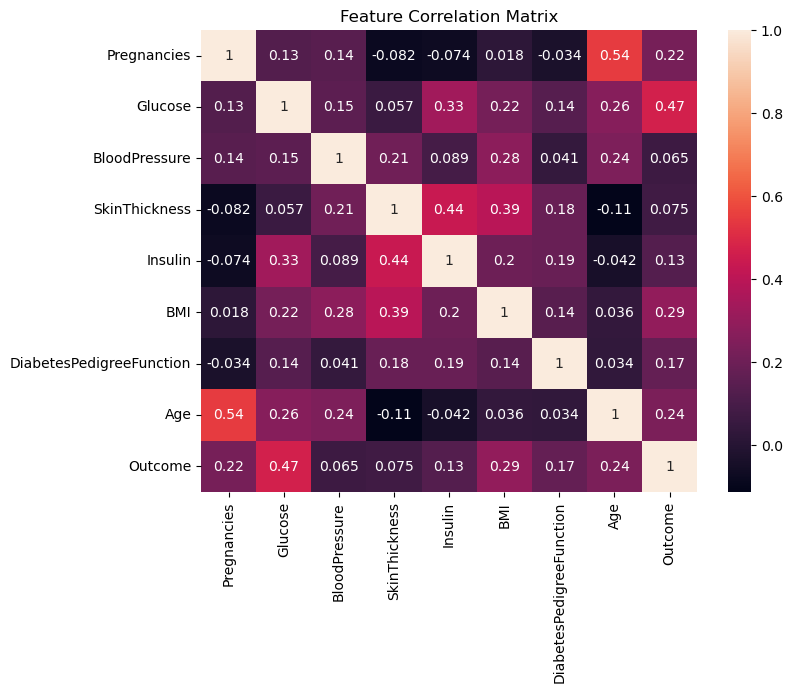

In [58]:
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True)
plt.title("Feature Correlation Matrix")
plt.show()

In [77]:
df_encoded = pd.get_dummies(df, drop_first=True)
##Separating the featutres and the target
y = df["Outcome"]
X = df.drop("Outcome", axis=1)
X = pd.get_dummies(X, drop_first=True)

In [78]:
cols = ["Glucose", "BloodPressure", "BMI", "Insulin"]

for col in cols:
    df[col] = df[col].replace(0, df[col].median())

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [61]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## ML MODEL ONE


In [79]:
from sklearn.model_selection import GridSearchCV

params = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 0.1, 0.01],
    'kernel': ['rbf'],
    'class_weight': [None, 'balanced']
}

grid = GridSearchCV(SVC(probability=True), params, cv=5)
grid.fit(X_train, y_train)

model = grid.best_estimator_
print("Best Params:", grid.best_params_)

Best Params: {'C': 10, 'class_weight': None, 'gamma': 'scale', 'kernel': 'rbf'}


In [80]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Make predictions on test data
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Show some predictions with probabilities
print("\nSample predictions (first 10 test samples):")
for i in range(10):
    print(f"Actual: {y_test.iloc[i]}, Predicted: {y_pred[i]}, Likelihood of Diabetes: {y_prob[i]:.2f}")

Accuracy: 0.77

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.84      0.82        99
           1       0.69      0.64      0.66        55

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.76      0.77      0.76       154


Confusion Matrix:
[[83 16]
 [20 35]]

Sample predictions (first 10 test samples):
Actual: 0, Predicted: 0, Likelihood of Diabetes: 0.43
Actual: 0, Predicted: 0, Likelihood of Diabetes: 0.25
Actual: 0, Predicted: 0, Likelihood of Diabetes: 0.19
Actual: 0, Predicted: 0, Likelihood of Diabetes: 0.16
Actual: 0, Predicted: 0, Likelihood of Diabetes: 0.40
Actual: 0, Predicted: 1, Likelihood of Diabetes: 0.67
Actual: 0, Predicted: 0, Likelihood of Diabetes: 0.04
Actual: 0, Predicted: 0, Likelihood of Diabetes: 0.49
Actual: 0, Predicted: 1, Likelihood of Diabetes: 0.66
Actual: 0, Predicted: 1, Likelihood of Diabetes: 0.55


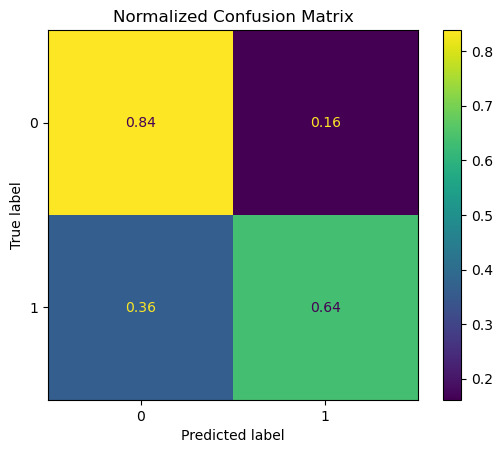

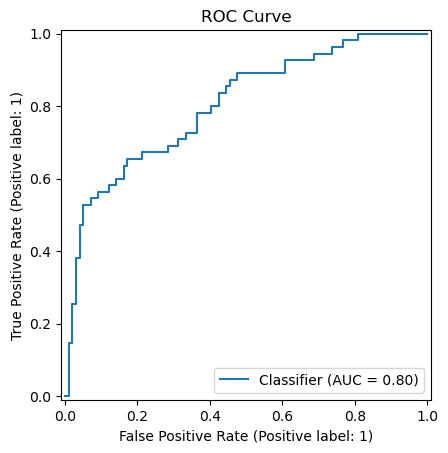

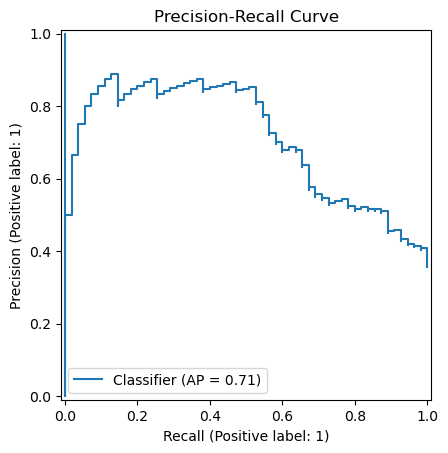

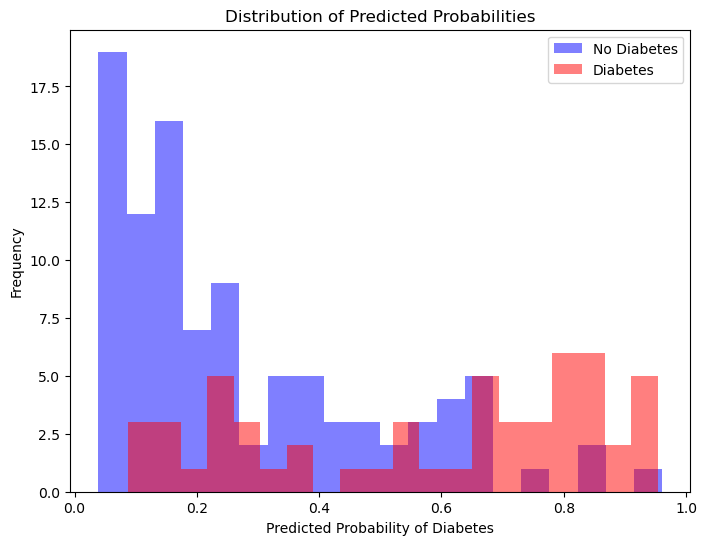

In [81]:
from sklearn.metrics import roc_curve, auc

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize='true')
plt.title("Normalized Confusion Matrix")
plt.show()

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve")
plt.show()

from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title("Precision-Recall Curve")
plt.show()
# Histogram of Predicted Probabilities
plt.figure(figsize=(8,6))
plt.hist(y_prob[y_test==0], bins=20, alpha=0.5, label='No Diabetes', color='blue')
plt.hist(y_prob[y_test==1], bins=20, alpha=0.5, label='Diabetes', color='red')
plt.xlabel('Predicted Probability of Diabetes')
plt.ylabel('Frequency')
plt.title('Distribution of Predicted Probabilities')
plt.legend()
plt.show()

In [82]:
from sklearn.metrics import recall_score

print("Recall:", recall_score(y_test, y_pred))

Recall: 0.6363636363636364


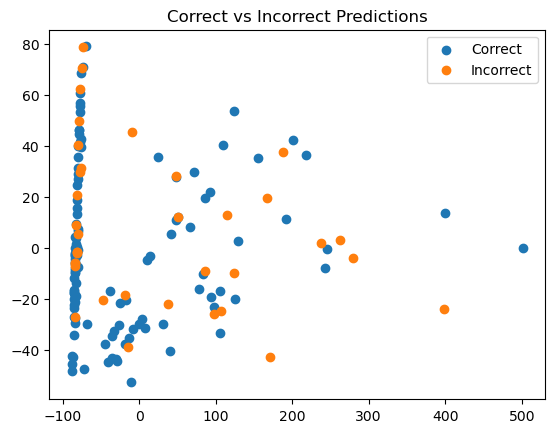

In [83]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train)  # fit on training data
X_test_pca = pca.transform(X_test)        # transform test data

correct = (y_pred == y_test.values)

plt.scatter(X_test_pca[correct, 0], X_test_pca[correct, 1], label="Correct")
plt.scatter(X_test_pca[~correct, 0], X_test_pca[~correct, 1], label="Incorrect")

plt.legend()
plt.title("Correct vs Incorrect Predictions")
plt.show()

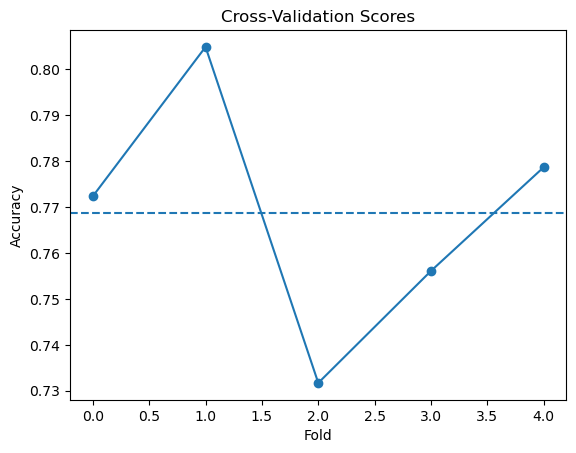

In [67]:
plt.plot(scores, marker='o')
plt.axhline(mean_score, linestyle='--')
plt.title("Cross-Validation Scores")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.show()

In [68]:
print(y.value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


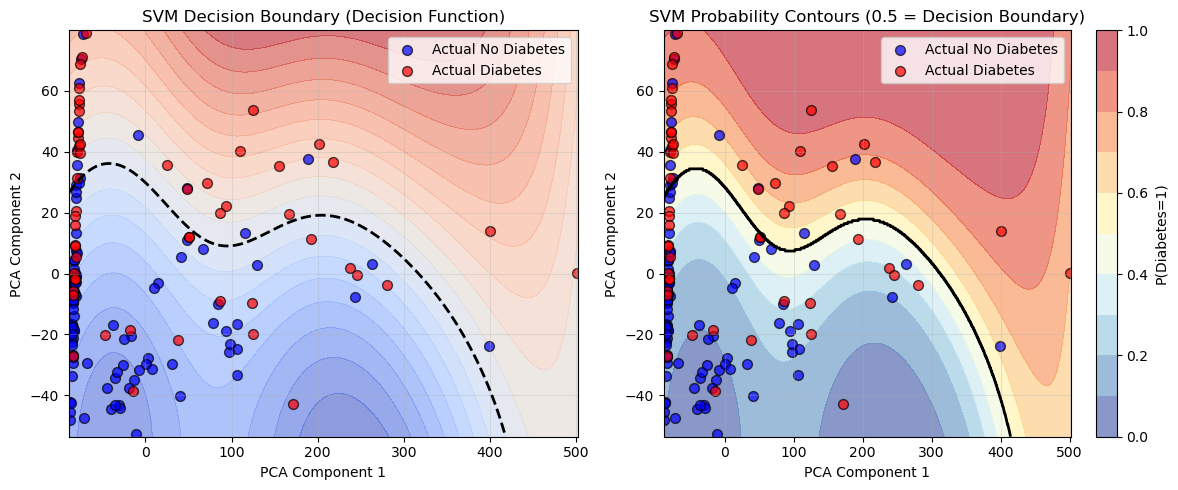

Decision boundary and probability maps displayed!


In [84]:
# Decision Boundary Plot in PCA 2D Space
x_min, x_max = X_test_pca[:, 0].min() - 1, X_test_pca[:, 0].max() + 1
y_min, y_max = X_test_pca[:, 1].min() - 1, X_test_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.5), np.arange(y_min, y_max, 0.5))

# Inverse transform grid back to original space
grid_pca = np.c_[xx.ravel(), yy.ravel()]
grid_orig = pca.inverse_transform(grid_pca)

# Get probabilities for the grid
prob_grid = model.predict_proba(grid_orig)[:, 1].reshape(xx.shape)

# Also get decision function
Z = model.decision_function(grid_orig).reshape(xx.shape)

# Plot 1: Decision Boundary with Decision Function
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.contourf(xx, yy, Z, levels=20, cmap='coolwarm', alpha=0.6)
plt.contour(xx, yy, Z, levels=[0], colors='black', linewidths=2, linestyles='dashed')
plt.scatter(X_test_pca[y_test == 0, 0], X_test_pca[y_test == 0, 1], 
            c='blue', s=50, alpha=0.7, label='Actual No Diabetes', edgecolors='k')
plt.scatter(X_test_pca[y_test == 1, 0], X_test_pca[y_test == 1, 1], 
            c='red', s=50, alpha=0.7, label='Actual Diabetes', edgecolors='k')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('SVM Decision Boundary (Decision Function)')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Probability Contours
plt.subplot(1, 2, 2)
plt.contourf(xx, yy, prob_grid, levels=np.linspace(0, 1, 11), cmap='RdYlBu_r', alpha=0.6)
plt.colorbar(label='P(Diabetes=1)')
plt.contour(xx, yy, prob_grid, levels=[0.5], colors='black', linewidths=2)
plt.scatter(X_test_pca[y_test == 0, 0], X_test_pca[y_test == 0, 1], 
            c='blue', s=50, alpha=0.7, label='Actual No Diabetes', edgecolors='k')
plt.scatter(X_test_pca[y_test == 1, 0], X_test_pca[y_test == 1, 1], 
            c='red', s=50, alpha=0.7, label='Actual Diabetes', edgecolors='k')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('SVM Probability Contours (0.5 = Decision Boundary)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Decision boundary and probability maps displayed!")

In [86]:
# Create a detailed prediction table
predictions_df = pd.DataFrame({
    'Predicted_Probability': y_prob,
    'Predicted_Class': y_pred,
    'Actual_Class': y_test.values,
    'Correct': y_pred == y_test.values
})

# Show first 20 predictions
print("=" * 80)
print("SAMPLE PREDICTIONS (First 20 Test Samples)")
print("=" * 80)
print(predictions_df.head(20).to_string(index=False))
print("\n" + "=" * 80)
print("SUMMARY STATISTICS")
print("=" * 80)
print(f"Total predictions: {len(predictions_df)}")
print(f"Correct predictions: {predictions_df['Correct'].sum()} ({100*predictions_df['Correct'].mean():.1f}%)")
print(f"Incorrect predictions: {(~predictions_df['Correct']).sum()} ({100*(~predictions_df['Correct']).mean():.1f}%)")
print(f"\nAverage probability for Diabetic patients (class=1): {y_prob[y_test==1].mean():.3f}")
print(f"Average probability for Non-Diabetic patients (class=0): {y_prob[y_test==0].mean():.3f}")

SAMPLE PREDICTIONS (First 20 Test Samples)
 Predicted_Probability  Predicted_Class  Actual_Class  Correct
              0.430399                0             0     True
              0.247063                0             0     True
              0.186716                0             0     True
              0.158093                0             0     True
              0.400657                0             0     True
              0.666657                1             0    False
              0.043096                0             0     True
              0.494403                0             0     True
              0.661900                1             0    False
              0.548861                1             0    False
              0.250607                0             1    False
              0.845083                1             0    False
              0.187552                0             1    False
              0.149001                0             0     True
            